I am interested in whether the recovery rates over time from drops in frequency below the minimum or increases above the maximum have increased or got worse. Also interested in how the variance of the power supply itself has changed. That could be interesting 

I would like to develop a statistic to model how quickly the grid recovers from drops in frequency each year. 
initially I would like to know how many times each year the frequency of the grid drops below the threshold 
we need to acquire all the frequency information for the past 10 years from the NESO API 
we are going to take this information, identify all the drops below and maybe above the threshold 

my initial thinking was to use the method they provided     

In [ ]:
#In the end, I was forced to manually download all the frequency files. 


maybe we should continue with the coding work tomorrow. It seems like we are getting a reasonable amount done, though it would be good to be able to produce some more statistics.
to summarise what needs to be done and what has been found: 
it appears that it might be possible to draw some kind of relationship between the weather and the response of the grid to the fluctuations in the power supply it that produces. We are currently reformatting all our data loading and statistical analysis stuff into classes to make it easier to introduce new methods. We might be somewhat overengineering though? maybe this isn't such a good idea? I like the statmethod class but not so sure about the other one. 
I would like to compute the recovery rates post frequency drop. I'm not really sure what frequency surges have to do in relation to grid resilience. might be worth looking into . It would also be good to look at the lag-1 autocorrelation prior to frequency drops. does it go up ? we've been learning about this AR(1) model, so we could have a go at fitting one of those. To understand the relationship between the weather and the grid we would need access to some more datasets, which is definitely possible 
it would also be good to look at the possible ways we can examine the data being provided in that other dataset we were looking at on the D drive. It would be both quite easy and helpful for the rest of the group to go to the trouble of producing some trend lines about how those things have changed over time, as a basic start point. 
it would also be good to find data on the mix of renewables over time and produce a plot to provide to the rest of the group. I don't really feel like the current level of statistical analysis would be sufficient for a final report. 
It would also be good to look into the data about regional blackouts, and try and understand the relationship between that and other factors related to the region, which might give indiciation of some caustivie relationships between variables. This needs some more research. 
As for some slightly more advanced statistical research: I quite like the weather-volatility relationship idea. that could potentially give some insight. needs more thought tho. I don't know what other more advanced statistical techniques could be used. we need to understand how to make confidence statements about the frequency data or other data. The random process we're observing is definitely an ornstein uhlenbeck process I think ? maybe that could provide some more insight. I'd be interested to see what gemma's up to

My only initial thoughts are about whether identifying initial signs prior to blackouts are helpful in quantifying grid resilience more generally. can we say that signs that appear before blackouts appearing more regularly in instances not related to blackouts is a sign that the resilience of the grid has gone down. Maybe we could look at network topology and see on average how well distributed the power is amongst the possible nodes. 
We are also supposed to be doing some economic stuff to understand the costs of all this . I'm not sure what peter will be producing, but ultimately that is a quesiton for later. We need to somewhat prioritise answering questions that move us closer to some kind of causitive relationship between time and grid resilience factors, and which gives us stuff to talk about on oyr cv for applying to fucking internships 
If you're looking for more information, just go look at the folder containing all this programming stuff, it will have a series of word documents 

In [16]:
import torch as t 
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 
import scipy
import os 


information about major outages that we want to find: 
unfortunately there only appear to have been two such occurrences 

In [ ]:
class StatMethods:
    def outage_integral(self, month_data):
        data = t.tensor((month_data)["f"].to_numpy())
        locs = t.where(abs(data - 50) > 0.2)
        return t.sum(t.abs(data[locs])) #this isn't correct, needs an update

    def minor_outage_freq(self, month_data):
        data = t.tensor((month_data)["f"].to_numpy())
        locs = t.where(abs(data - 50) > 0.2)
        return len(data[locs])
    
    def major_outage_instances(self, month_data):
        data = t.tensor(month_data["f"].to_numpy())
        locs = t.where(abs(data-50) > 0.5)
        return data[locs]
    
    def major_outage_periods(self, month_data):


In [26]:
class DataLoader:
    def __init__(self, directory, years, months):
        self.directory = directory
        self.years = years
        self.months = months 

    def get_file_location(self, year, month):
        poss_formats = [f"f-{year}-{month}.csv", f"fnew-{year}-{month}.csv", f"fNew {year} {month}.csv", f"f {year} {month}.csv"]
        for x in poss_formats:
            path = os.path.join(self.directory, x)
            if os.path.exists(path):
                print(f"found {year}/{month}")
                return path 
        raise FileNotFoundError(F"couldn't find file {year}/{month} with any of the specified formats")

    def run_on_data(self, func):
        output = []
        for year in self.years:
            for month in self.months:
                loc = self.get_file_location(year, month)
                data = pd.read_csv(loc)
                output.append(func(data))
                print(f"{year}/{month} evaluated")
        return output 



In [ ]:
directory = "D:/group project data/frequency_data"
years =  [x for x in range(2016, 2026)]
months = [x for x in range(1, 13)]

dataloader = DataLoader(directory, years, months)
stats = StatMethods()
result = dataloader.run_on_data(stats.major_outage_instances)
print(result)   

#is there a more efficient way of running this code 


found 2016/1
2016/1 evaluated
found 2016/2
2016/2 evaluated
found 2016/3
2016/3 evaluated
found 2016/4
2016/4 evaluated
found 2016/5
2016/5 evaluated
found 2016/6
2016/6 evaluated
found 2016/7
2016/7 evaluated
found 2016/8
2016/8 evaluated
found 2016/9
2016/9 evaluated
found 2016/10
2016/10 evaluated
found 2016/11
2016/11 evaluated
found 2016/12
2016/12 evaluated
found 2017/1
2017/1 evaluated
found 2017/2
2017/2 evaluated
found 2017/3
2017/3 evaluated
found 2017/4
2017/4 evaluated
found 2017/5
2017/5 evaluated
found 2017/6
2017/6 evaluated
found 2017/7
2017/7 evaluated
found 2017/8
2017/8 evaluated
found 2017/9
2017/9 evaluated
found 2017/10
2017/10 evaluated
found 2017/11
2017/11 evaluated
found 2017/12
2017/12 evaluated
found 2018/1
2018/1 evaluated
found 2018/2
2018/2 evaluated
found 2018/3
2018/3 evaluated
found 2018/4
2018/4 evaluated
found 2018/5
2018/5 evaluated
found 2018/6
2018/6 evaluated
found 2018/7
2018/7 evaluated
found 2018/8
2018/8 evaluated
found 2018/9
2018/9 evaluate

In [38]:
print(type(result))
outage_months = []
for x in range(len(result)):
    if result[x].numel() != 0:
        print(result[x])
        outage_months.append(x)

print(outage_months)
for x in outage_months:
    year = 2014 + (x-1)//12
    month = (x-1)%12 + 1
    print(f"{year}/{month}")

<class 'list'>
tensor([49.4680, 49.4280, 49.3720, 49.3310, 49.2940, 49.2720, 49.2740, 49.2250,
        49.2050, 49.1970, 49.1730, 49.1510, 49.1360, 49.1310, 49.1260, 49.1410,
        49.1410, 49.0850, 49.1070, 49.1170, 49.1200, 49.0830, 49.1280, 49.1050,
        49.1000, 49.1520, 49.1360, 49.1130, 49.1330, 49.1500, 49.1600, 49.1680,
        49.1730, 49.1820, 49.2280, 49.2230, 49.2310, 49.2340, 49.2170, 49.2680,
        49.2250, 49.2380, 49.2350, 49.2140, 49.2640, 49.2000, 49.2580, 49.2110,
        49.1920, 49.2450, 49.2080, 49.1880, 49.1710, 49.1920, 49.1700, 49.1210,
        49.0930, 49.0720, 49.0900, 49.0510, 49.0090, 49.0050, 49.0000, 48.9830,
        48.9430, 48.9640, 48.9120, 48.8920, 48.8680, 48.8420, 48.8150, 48.7870,
        48.8210, 48.8370, 48.8530, 48.8680, 48.8770, 48.8970, 48.8700, 48.9190,
        48.9320, 48.9220, 48.9410, 48.9050, 48.9150, 48.9280, 48.8860, 48.9190,
        48.9020, 48.9240, 48.9300, 48.9440, 48.9280, 48.9640, 48.9400, 48.9730,
        49.0010, 49.0190,

In [ ]:
def write_monthly_to_csv(data, filename, start_date: tuple, end_date: tuple): #don't include a .csv in the filename, it will be added 
    start_year, start_month = start_date[0], start_date[1]
    end_year, end_month = end_date[0], end_date[1]
    csv_year_column = []
    csv_month_column = []
    for month in range(start_month, 13):
        csv_year_column.append(start_year)
        csv_month_column.append(month)
    for year in range(start_year+1, end_year):
        for month in range(1, 13):
            csv_year_column.append(year)
            csv_month_column.append(month)
    for month in range(1, end_month +1):
        csv_year_column.append(end_year)
        csv_month_column.append(month)
        
    if len(csv_month_column) != len(data):
        print(f"month column length is {len(csv_month_column)}, but data length is {len(data)}")
        raise IndexError("the lengths of the month and data columns are different")
    if len(csv_year_column) != len(data):
        print(f"year column length is {len(csv_year_column)}, but data length is {len(data)}")
        raise IndexError("the lenghts of the year and data column are different")

    df = pd.DataFrame({"year": csv_year_column, "month": csv_month_column, "data": data} )
    df.to_csv("../output_data/" + filename + ".csv", index=False)


    #the loop is split into three sections to ensure that, if the data doesn't start in january, the entire first year is covered
    #the final loop ensures that if the data doesn't end at the final month of hte final year, the final year is covered without overrunning the data

In [ ]:
write_monthly_to_csv(result, "monthly_minor_outage_frequency", (2016, 1), (2025, 12)) #works  !

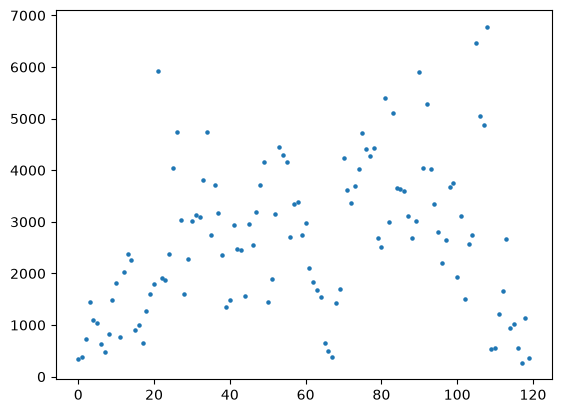

In [ ]:
plt.scatter([x for x in range(len(result))], result, s=5)

In [77]:
from scipy.stats import pearsonr
def best_fit(x, y):
    m, c = np.polyfit(x, y, 1)
    r, p_value = pearsonr(x, y)
    return m, c, r, p_value